In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [23]:
# Read grayscale image
img = cv2.imread('image.jpeg', 0)
row, col = img.shape

In [24]:
# Fourier Transform
F = np.fft.fftshift(np.fft.fft2(img))
F

array([[  18.28141998-242.18030233j,  -56.05439939+306.03005405j,
        -239.41240045-244.49904662j, ..., -239.41240045+244.49904662j,
         -56.05439939-306.03005405j,   18.28141998+242.18030233j],
       [ 260.13113201+236.99898233j, -185.00234854 -65.74842063j,
         128.20439816 -83.70692817j, ...,   79.22723047-437.38642454j,
         271.81711649+302.79805023j, -230.69814136-251.94673317j],
       [-571.4181268 +370.13717686j,  219.74397137-398.67601491j,
         -11.73006522+553.34819766j, ...,   99.97445289+158.93117513j,
        -494.5299593  -91.69771867j,  721.07586302-155.93975025j],
       ...,
       [-828.88153648  -7.76675234j,  803.47087167 +26.72470103j,
        -431.37573128-129.0410071j , ..., -340.55749411+298.79464475j,
          95.04329412-331.48601623j,  554.29032452+250.69784568j],
       [ 721.07586302+155.93975025j, -494.5299593  +91.69771867j,
          99.97445289-158.93117513j, ...,  -11.73006522-553.34819766j,
         219.74397137+398.67601491j

In [25]:
# Calculate distance from frequency center
u, v = np.meshgrid(np.arange(row), np.arange(col), indexing='ij')
D = np.sqrt((u - row/2)**2 + (v - col/2)**2)

In [26]:
# Filter parameters
D0 = 50
n = 2

In [27]:
# 1. Ideal Low Pass Filter
ideal_lp = np.zeros((row, col))
ideal_lp[D <= D0] = 1

# 2. Butterworth Low Pass Filter
butter_lp = 1 / (1 + (D / D0)**(2*n))

# 3. Gaussian Low Pass Filter
gaussian_lp = np.exp(-(D**2) / (2 * D0**2))

In [28]:
# Apply filters and get inverse Fourier Transform
def apply_filter(H):
    G = F * H
    result = np.fft.ifft2(np.fft.ifftshift(G))
    return np.clip(np.real(result), 0, 255).astype(np.uint8)

In [29]:
# Low Pass Results
ideal_low = apply_filter(ideal_lp)
butter_low = apply_filter(butter_lp)
gaussian_low = apply_filter(gaussian_lp)

# High Pass Filters
ideal_high = apply_filter(1 - ideal_lp)
butter_high = apply_filter(1 - butter_lp)
gaussian_high = apply_filter(1 - gaussian_lp)

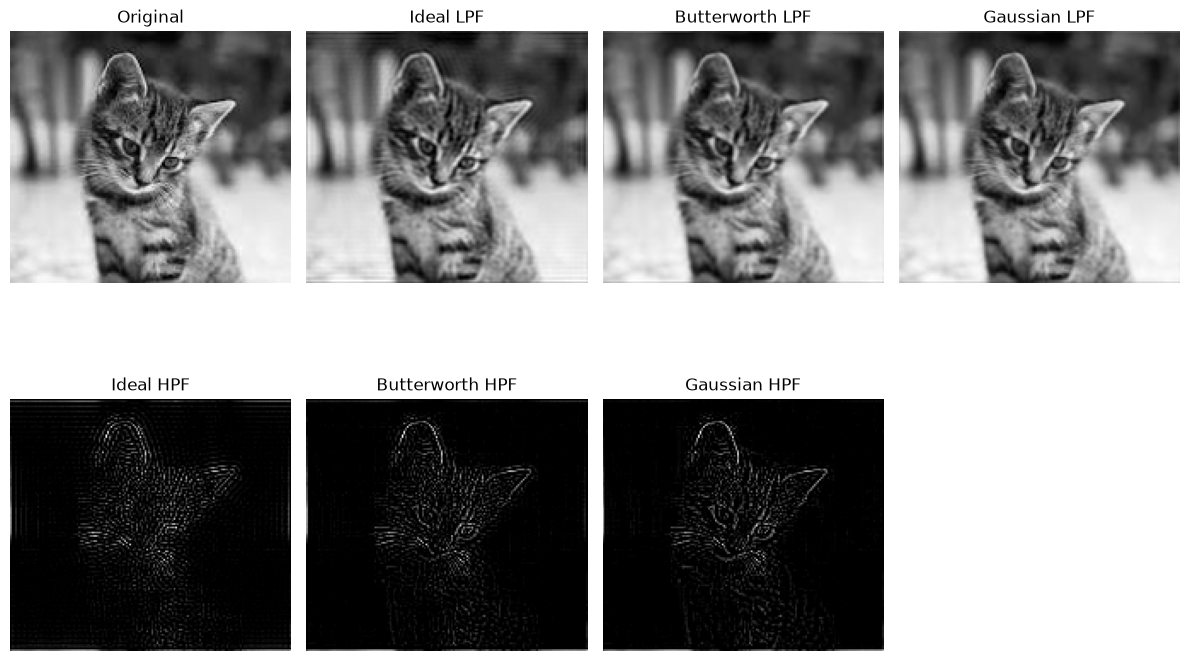

In [30]:
# Display Results
images = [img, ideal_low, butter_low, gaussian_low,
          ideal_high, butter_high, gaussian_high]

titles = ['Original', 'Ideal LPF', 'Butterworth LPF',
          'Gaussian LPF', 'Ideal HPF', 'Butterworth HPF',
          'Gaussian HPF']

plt.figure(figsize=(12, 8))

for i in range(7):
    plt.subplot(2, 4, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()